<style>
table {
    display: block;
    overflow-x: auto;
    white-space: nowrap;
}
</style>


# Exercise 02

## Author Roohullah Amin

In [2]:
setwd = "Desktop/Environmental change/Lab/Ex_02"

In [3]:
# Libraries
#install.packages("ade4")
library(ade4)
#install.packages("vegan")
library(vegan)
library(ecodist)

Loading required package: permute


Attaching package: ‘ecodist’


The following objects are masked from ‘package:vegan’:

    mantel, pco




In [4]:
# Loading the dataset

## Species traits
t <-read.csv("Traits_80sp.csv", row.names=1)

# Mean traits per site
trait <- read.csv("Mean traits per site.csv",row.names=1)
trait <- log(trait)
trait <- trait[,-17]# omit number of species

## Abundance data
occ1 <- read.csv("Abundance_80sp.csv",sep =",", row.names=1)
occ1 <- decostand(occ1, "hellinger") # standardization methods for abundance data

## Traits as factors
fact_t <- read.csv("Factor_traits_80sp.csv", row.names=1)

## Load environmental data

env <- read.csv("Environmental_parameters1.csv",row.names=1)

In [5]:


#1.Let´s transform the data using log function.

## We need to log transform the trait data for further analyses

t[,6]<-log(t[,6])
t[,7]<-log(t[,7])
t[,8]<-log(t[,8])
t[,9]<-log(t[,9])
t[,10]<-log(t[,10])

# Mean traits per site
trait <- read.csv("Mean traits per site.csv",row.names=1)
trait <- log(trait)
trait <- trait[,-17]# omit number of species

## Abundance data
occ1 <- read.csv("Abundance_80sp.csv",sep =",", row.names=1)
occ1 <- decostand(occ1, "hellinger") # standardization methods for abundance data

In [6]:
## How to solve the problems of names species.
rownames(t)
colnames(occ1)
species <- colnames(occ1)
rownames(t) <- species
species
head(t)



## Traits as factors
fact_t <- read.csv("Factor_traits_80sp.csv", row.names=1)

## Load environmental data

env <- read.csv("Environmental_parameters1.csv",row.names=1)
# only for rlq

env <- log(env)
env <- env[,-4]# omit the variable n? of individuals
#env <- env[,-4]# omit the variable area of sites only for ordinations

env[is.na(env)] <- 0

[1] "alchor.trip" "alib.con"    "anaden"      "atta"        "banis"      
 [6] "Byr.398sp"   "Byr.461sp"   "cabrale"     "cari"        "casea.si"   
[11] "cedre"       "cedre.odo"   "cletra"      "copa"        "coussa"     
[16] "crypo.mos"   "cup.ver"     "dalber."     "dice"        "ficus"      
[21] "gomi.463sp"  "gomi.87sp"   "gomi.af"     "guapi.op"    "guate.281"  
[26] "guate.504"   "guate.aus"   "hetero.ma"   "jacara.sp1"  "jacara.sp2" 
[31] "laura sp1"   "laura sp2"   "macha.br"    "mani"        "mata"       
[36] "mi.143"      "mi.19"       "mi.206"      "mi.236"      "myrse"      
[41] "nec"         "oco.170"     "oco.171"     "oco.225"     "oco.286"    
[46] "oco.293"     "oco.471"     "oco.48"      "oco.64"      "oco.cory"   
[51] "paulli"      "pera "       "piper"       "plasty"      "poso"       
[56] "psyc.147"    "psyc.90"     "psyc.lei"    "psyc.su"     "rolli"      
[61] "rudge"       "sloan.gui"   "sloan.mo"    "so.116"      "so.150"     
[66] "so.152"      "so.323"      "so.324"      "so.340"      "so.351"     
[71] "so.43"       "so.525"      "so.59"       "so.73"       "so.93"      
[76] "styr"        "tabe.alba"   "tabe.casse"  "tibou"       "viro"

[1] "alchor.trip" "alib.con"    "anaden"      "atta"        "banis"      
 [6] "Byr.398sp"   "Byr.461sp"   "cabrale"     "cari"        "casea.si"   
[11] "cedre.odo"   "cedre"       "cletra"      "copa"        "crypo.mos"  
[16] "cup.ver"     "coussa"      "dalber."     "dice"        "ficus"      
[21] "gomi.87sp"   "gomi.463sp"  "gomi.af"     "guapi.op"    "guate.281"  
[26] "guate.504"   "guate.aus"   "hetero.ma"   "jacara.sp1"  "jacara.sp2" 
[31] "laura.sp1"   "laura.sp2"   "macha.br"    "mani"        "mata"       
[36] "mi.19"       "mi.143"      "mi.206"      "mi.236"      "myrse"      
[41] "nec"         "oco.170"     "oco.171"     "oco.225"     "oco.286"    
[46] "oco.293"     "oco.471"     "oco.48"      "oco.64"      "oco.cory"   
[51] "paulli"      "pera"        "piper"       "plasty"      "poso"       
[56] "psyc.147"    "psyc.90"     "psyc.lei"    "psyc.su"     "rolli"      
[61] "rudge"       "sloan.gui"   "sloan.mo"    "so.43"       "so.59"      
[66] "so.73"       "so.93"       "so.116"      "so.150"      "so.152"     
[71] "so.323"      "so.324"      "so.340"      "so.351"      "so.525"     
[76] "styr"        "tabe.alba"   "tabe.casse"  "tibou"       "viro"

[1] "alchor.trip" "alib.con"    "anaden"      "atta"        "banis"      
 [6] "Byr.398sp"   "Byr.461sp"   "cabrale"     "cari"        "casea.si"   
[11] "cedre.odo"   "cedre"       "cletra"      "copa"        "crypo.mos"  
[16] "cup.ver"     "coussa"      "dalber."     "dice"        "ficus"      
[21] "gomi.87sp"   "gomi.463sp"  "gomi.af"     "guapi.op"    "guate.281"  
[26] "guate.504"   "guate.aus"   "hetero.ma"   "jacara.sp1"  "jacara.sp2" 
[31] "laura.sp1"   "laura.sp2"   "macha.br"    "mani"        "mata"       
[36] "mi.19"       "mi.143"      "mi.206"      "mi.236"      "myrse"      
[41] "nec"         "oco.170"     "oco.171"     "oco.225"     "oco.286"    
[46] "oco.293"     "oco.471"     "oco.48"      "oco.64"      "oco.cory"   
[51] "paulli"      "pera"        "piper"       "plasty"      "poso"       
[56] "psyc.147"    "psyc.90"     "psyc.lei"    "psyc.su"     "rolli"      
[61] "rudge"       "sloan.gui"   "sloan.mo"    "so.43"       "so.59"      
[66] "so.73"       "so.93"       "so.116"      "so.150"      "so.152"     
[71] "so.323"      "so.324"      "so.340"      "so.351"      "so.525"     
[76] "styr"        "tabe.alba"   "tabe.casse"  "tibou"       "viro"

,Shade.Tolerant,Shade.Intolerant,Shade.Intermediate,Zoochorous,Anemochorous,Seed.length,Seed.mass,Fruit.length,Fruit.width,Fruit.mass
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
alchor.trip,0,1,0,1,0,-0.4004776,0.3364722,1.7047481,2.0668628,0.09531018
alib.con,1,0,0,1,0,-0.4155154,-0.3147107,2.5176965,2.1459313,2.72129543
anaden,0,1,0,0,1,0.1310283,0.4054651,5.0291299,2.7536607,2.90142159
atta,0,0,1,1,0,0.2546422,2.1972246,3.9080150,3.3520071,3.31962573
banis,0,1,0,0,1,-0.1863296,-0.5978370,3.3775875,2.4932055,-0.82098055
Byr.398sp,1,0,0,1,0,-0.2107210,-0.3285041,0.1988509,0.5128236,0.40546511


NULL

Duality diagramm
class: mix dudi
$call: dudi.hillsmith(df = t, scannf = FALSE, nf = 2)

$nf: 2 axis-components saved
$rank: 8
eigen values: 2.657 2.094 1.792 1.269 0.7397 ...
  vector length mode    content       
1 $cw    10     numeric column weights
2 $lw    80     numeric row weights   
3 $eig   8      numeric eigen values  

  data.frame nrow ncol content             
1 $tab       80   10   modified array      
2 $li        80   2    row coordinates     
3 $l1        80   2    row normed scores   
4 $co        10   2    column coordinates  
5 $c1        10   2    column normed scores
other elements: assign index cr center norm 

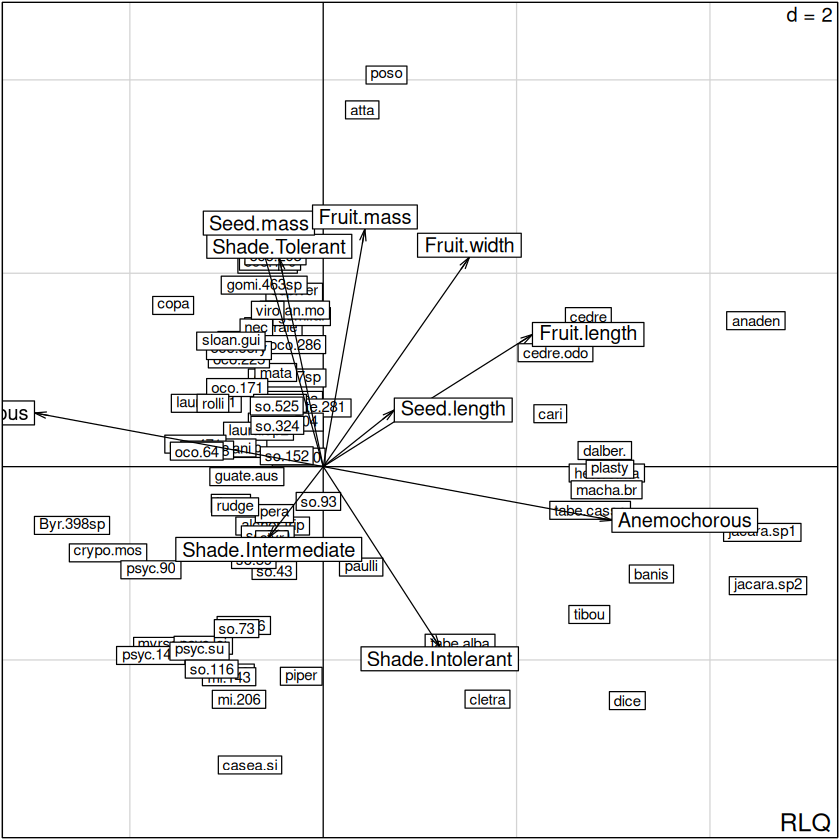

In [37]:
#2.Let´s run an ordination: Species in the trait space

coa1 <- dudi.coa(occ1, scannf = FALSE, nf = 2) ## ordination for abundances of species
duditrait <- dudi.hillsmith(t, scannf = FALSE, nf = 2) # ordination for species traits
biplot(duditrait, sub= "RLQ",posieig= "none",nf=2, scannf = FALSE, type = "t")

duditrait


In [ ]:
## How to calculate the explained variance for each pca axis of the ordination
duditrait$eig[1]/sum(duditrait$eig)*100 # almost 27% of the marginality in the data set % in the first axes
duditrait$eig[2]/sum(duditrait$eig)*100 # together , the 2 axes account for 20% of the marginality

## Question:1. What are the main dispersal mode of plant species? How can I see the eigenvalues and eigenvectors of those points?
duditrait$c1 ## here are the eigenvalues for each axis per trait
duditrait$li ## as in a pca these are the coefficients 

[1] 26.56725

[1] 20.93516

,CS1,CS2
,<dbl>,<dbl>
Shade.Tolerant,-0.08591572,0.4075974
Shade.Intolerant,0.22793781,-0.3525852
Shade.Intermediate,-0.10656440,-0.1385359
Zoochorous,-0.56485336,0.1050457
Anemochorous,0.56485336,-0.1050457
Seed.length,0.13913004,0.1106864
Seed.mass,-0.12582680,0.4529875
Fruit.length,0.40935155,0.2584914
Fruit.width,0.28596356,0.4096592


,Axis1,Axis2
,<dbl>,<dbl>
alchor.trip,-0.52270237,-0.6146326
alib.con,-0.57508828,2.0933974
anaden,4.47512771,1.5093463
atta,0.40343248,3.6896584
banis,3.39483302,-1.1104888
Byr.398sp,-2.59835601,-0.6083482
Byr.461sp,-0.70062979,1.3044443
cabrale,-0.51556162,1.4477772
cari,2.34849470,0.5472125


In [16]:
##For your assignment; please answer the following questions:

# Q1: Is there any clear gradient within species and functional traits?

# Q2: Which trait has higher association with axis 1? and which with axis 2?

# Q3: Are anemochorous species more shade intolerant?

#3.Ordination plot: Sites in the environmental space

NULL

[1] 45.41312

[1] 25.14638

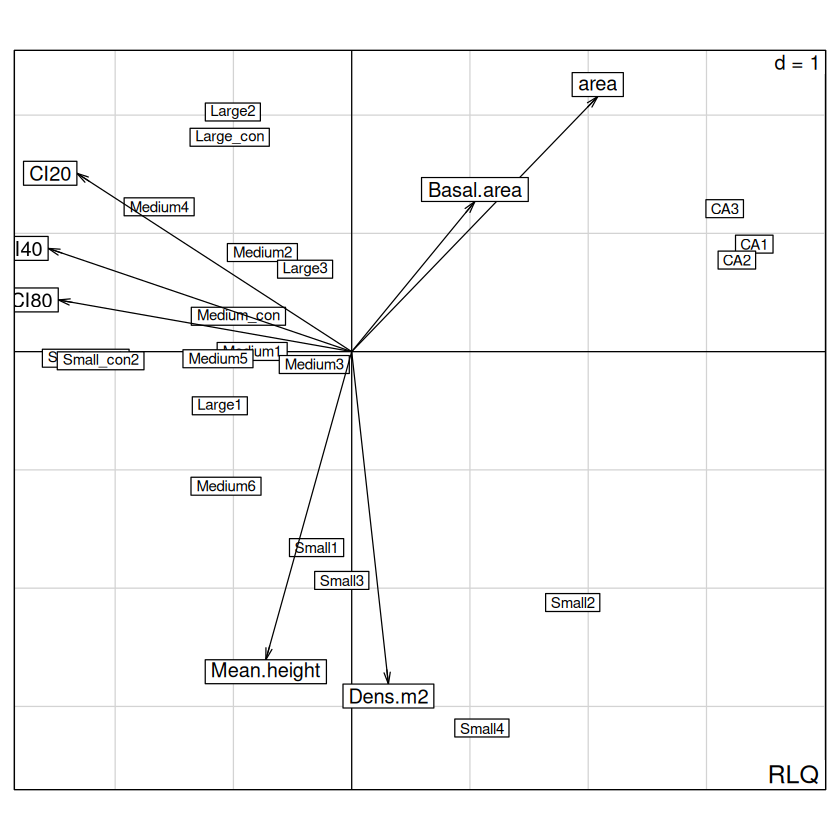

In [20]:
#3.Ordination plot: Sites in the environmental space

par(oma=c(2,0.5,2,0.5))
dudienv <- dudi.hillsmith(env, scannf = FALSE, nf = 2, row.w = coa1$lw)
biplot(dudienv, sub= "RLQ",posieig= "none",nf=4, scannf = FALSE, type = "p", col= c("red",dudienv$l1[,1]))

dudienv$eig[1]/sum(dudienv$eig)*100 # almost 45% of the marginality in the dataset % in the firt axes
dudienv$eig[2]/sum(dudienv$eig)*100 # together , the 2 axes account for 70% of the marginality


#Considering this ordination, please answer the question:

#Q4: What is the main trend in this ordination?



NULL

[1] 28.46771

[1] 23.22025

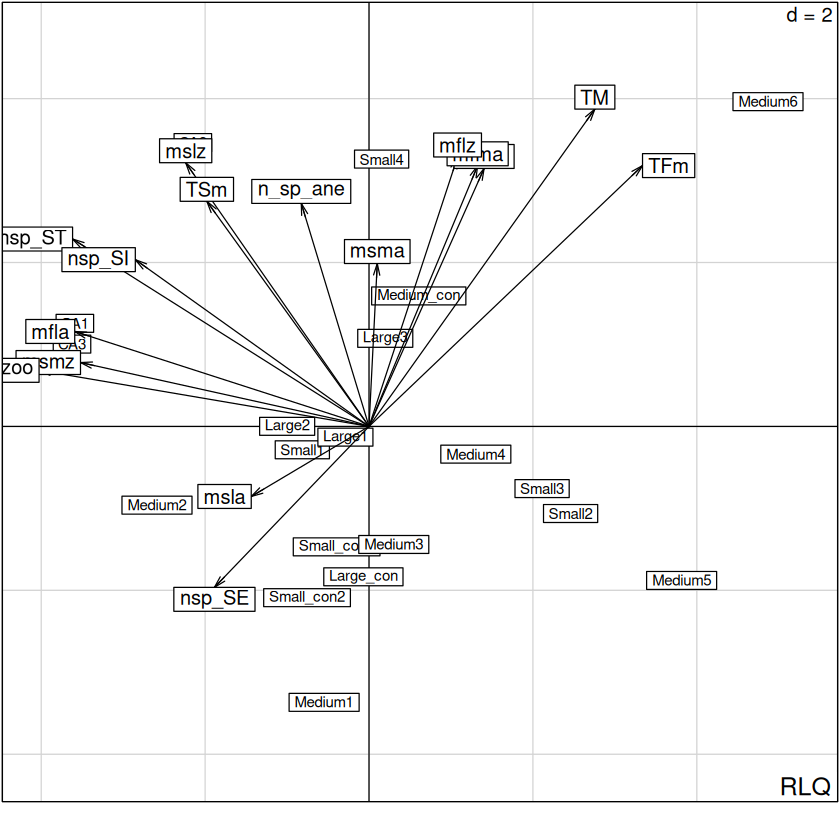

In [9]:
#4.Ordination Plot: Sites in the mean trait per site space

par(oma=c(1.5,0,0,0))
pca1 <- dudi.pca(trait, scan = FALSE, nf = 2, col.w = rep(1, ncol(trait)))
biplot(pca1, sub= "RLQ",posieig= "none",nf=2, scannf = FALSE, type = "n")


pca1$eig[1]/sum(pca1$eig)*100 # almost 28% of the marginality in the dataset % in the firt axes
pca1$eig[2]/sum(pca1$eig)*100 # together , the 2 axes account for 51% of the marginality



In [10]:
#the table of weighted means is constructed by matrix of multiplication
cwm.tab <- prop.table(as.matrix(occ1),1)%*%as.matrix(scale(t))
pca.cwm <- dudi.pca(cwm.tab,scannf=F)
rda.cwm <- pcaiv(pca.cwm, env, scannf=F)



[1] 48.35747

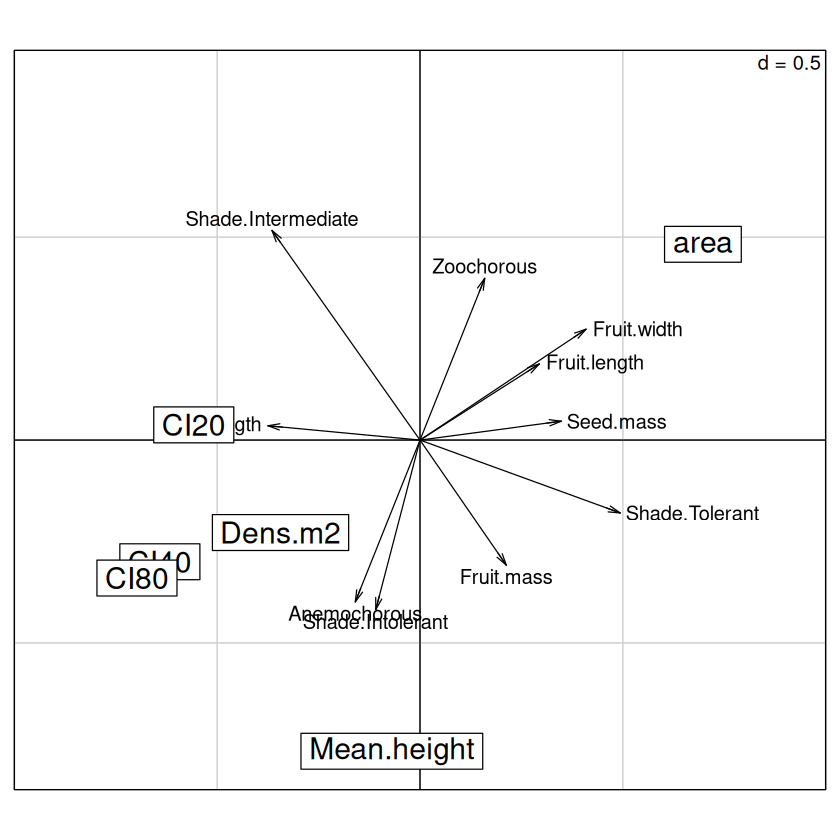

In [11]:
# % of variation in community traits explained by environment
par(oma=c(2,0.5,2,0.5))
100*sum(rda.cwm$eig / sum(pca.cwm$eig))
s.arrow(rda.cwm$c1, xlim=c(-1,1), boxes=F)
s.label(rda.cwm$cor[-1,],add.plot=T,clab=1.5)



In [12]:
# the % of explained variation associated to each axis:
pca.cwm <- dudi.pca(cwm.tab, scannf=F)
100*rda.cwm$eig /sum(rda.cwm$eig)

[1] 46.57408880 26.72839637 17.65696757  3.88871915  2.58232377  2.51528088
[7]  0.05422345

In [14]:
#Please answer the following question:

#Q5) Based on the ordination of site on trait space, can you describe the main gradient between site and traits?

#Q6) How much variance is shown by PC1 explaining the variance of traits by sites parameters?

Fourth-corner Statistics
------------------------
Permutation method  1  ( 9999  permutations)

Adjustment method for multiple comparisons:   holm 
call:  fourthcorner(tabR = env, tabL = occ1, tabQ = t, modeltype = 1,      nrepet = 9999) 

---

                               Test Stat           Obs       Std.Obs     Alter
1       Basal.area / Shade.Tolerant    r -0.0001483993  0.0027359515 two-sided
2          Dens.m2 / Shade.Tolerant    r -0.0291659149 -0.8273970515 two-sided
3      Mean.height / Shade.Tolerant    r  0.0013959396  0.0366004357 two-sided
4             area / Shade.Tolerant    r  0.0592030845  1.6958666385 two-sided
5             CI20 / Shade.Tolerant    r -0.0728063399 -2.0967231182 two-sided
6             CI40 / Shade.Tolerant    r -0.0628764889 -1.8030735148 two-sided
7             CI80 / Shade.Tolerant    r -0.0653099832 -1.8640014467 two-sided
8     Basal.area / Shade.Intolerant    r -0.0170793104 -0.4724996396 two-sided
9        Dens.m2 / Shade.Intolerant    r  0.

Fourth-corner Statistics
------------------------
Permutation method  1  ( 9999  permutations)

Adjustment method for multiple comparisons:   holm 
                               Test Stat           Obs       Std.Obs     Alter
1       Basal.area / Shade.Tolerant    r -0.0001483993  0.0027359515 two-sided
2          Dens.m2 / Shade.Tolerant    r -0.0291659149 -0.8273970515 two-sided
3      Mean.height / Shade.Tolerant    r  0.0013959396  0.0366004357 two-sided
4             area / Shade.Tolerant    r  0.0592030845  1.6958666385 two-sided
5             CI20 / Shade.Tolerant    r -0.0728063399 -2.0967231182 two-sided
6             CI40 / Shade.Tolerant    r -0.0628764889 -1.8030735148 two-sided
7             CI80 / Shade.Tolerant    r -0.0653099832 -1.8640014467 two-sided
8     Basal.area / Shade.Intolerant    r -0.0170793104 -0.4724996396 two-sided
9        Dens.m2 / Shade.Intolerant    r  0.0247167337  0.6518911287 two-sided
10   Mean.height / Shade.Intolerant    r  0.0490075786  1.2900

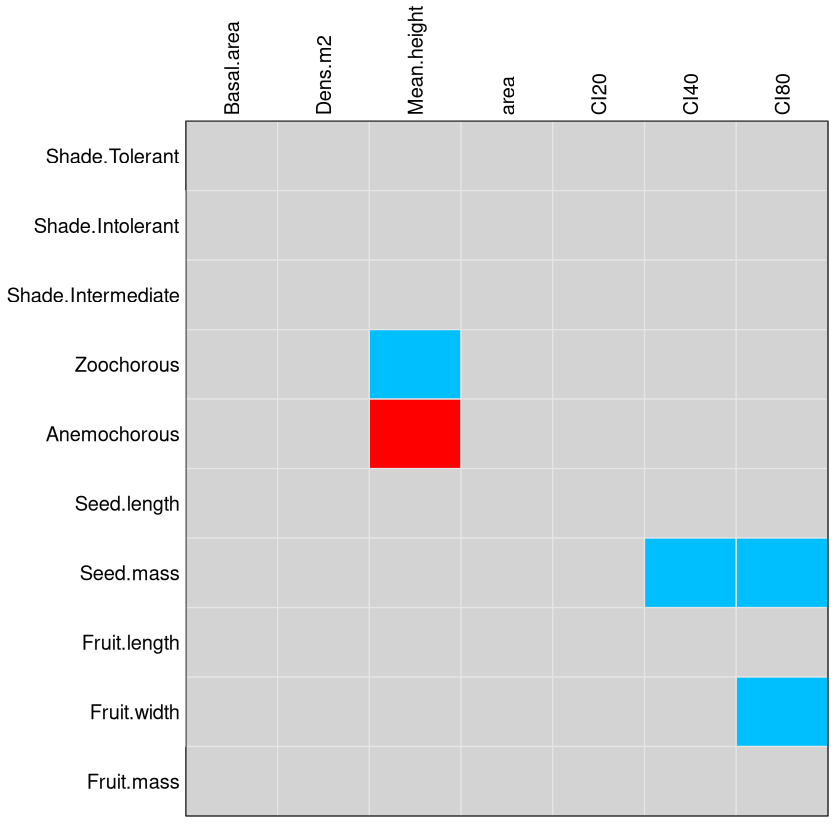

In [15]:
#5.Fourth corner analysis (separated data) For this analysis na of thetraits table should be taken out Calculating 4th corner for each trait data

# env need to include area of sites
four1<-fourthcorner(env,occ1,t, modeltype = 1, nrepet=9999)
four1
summary(four1)
## ploting after the change at the main library
plot(four1, stat = c("G"), type = "table", xax = 1, yax = 2, x.rlq = NULL, alpha = 1) # blue positive relationships and red negative
# red colors mean positive relationship (look at the estimates signal)

In [16]:
##Please answer the following questions:

# Q7) How would you explain the positive correlation between area of fragments and seeds/fruits?

# Q8) Why seeds dispersed by wind are negatively correlated with the area of the forest?

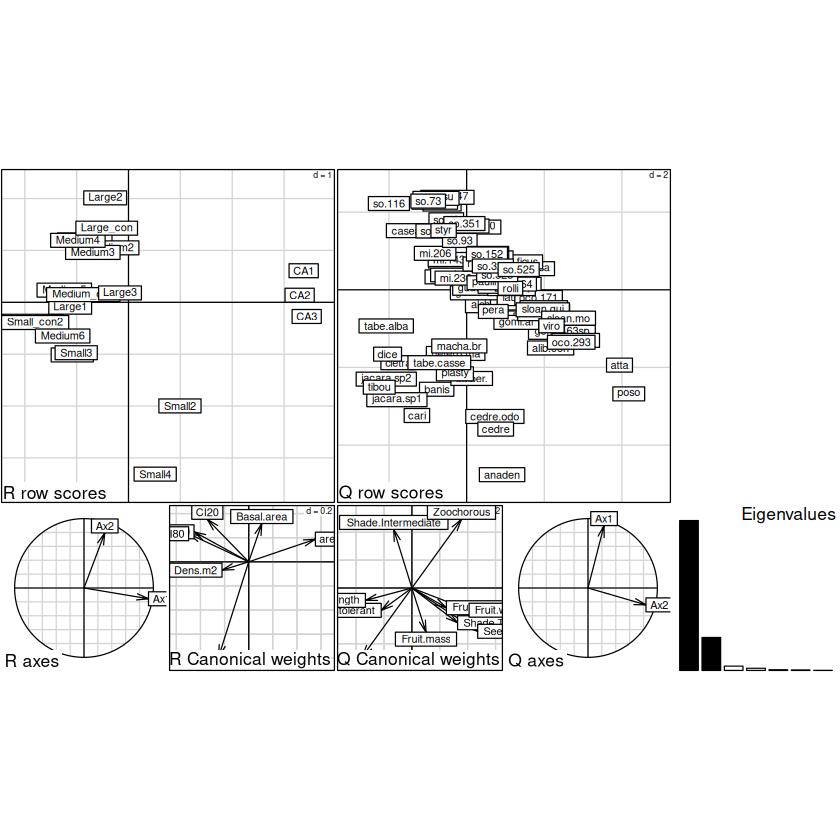

In [17]:
#6.RLQ analysis


# Analysis with T1 
coa1 <- dudi.coa(occ1, scannf = FALSE, nf = 2)
dudienv1 <- dudi.hillsmith(env, scannf = FALSE, nf = 2, row.w = coa1$lw)
duditrait1 <- dudi.hillsmith(t, scannf = FALSE, nf = 2, row.w = coa1$cw)
rlq1 <- rlq(dudienv1, coa1, duditrait1, scannf = FALSE, nf = 2)
plot(rlq1)

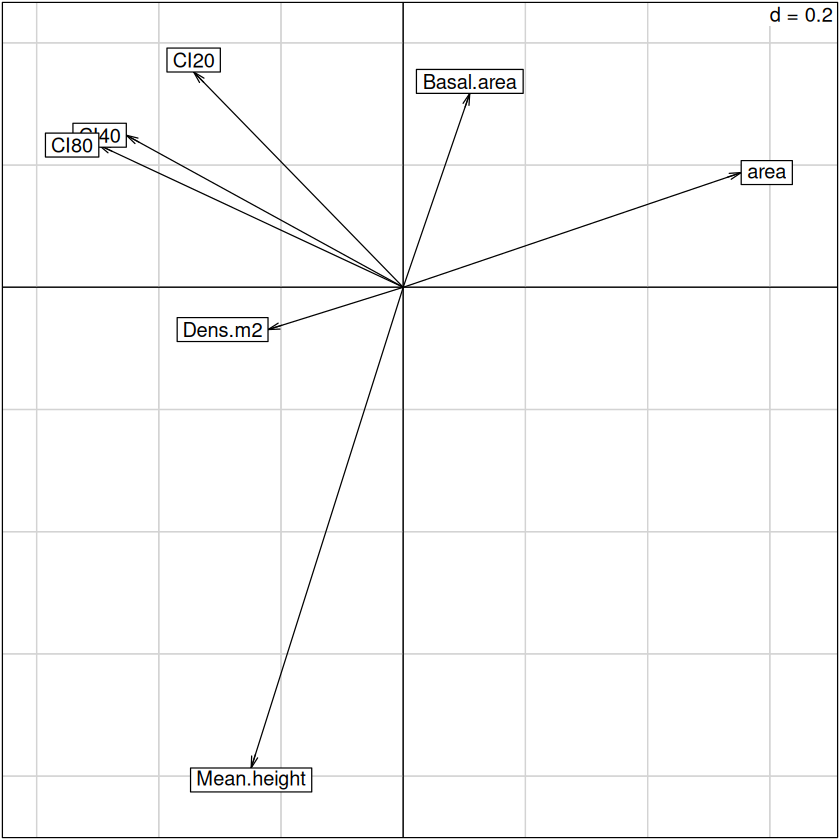

In [20]:
### ploting separately
par(mfrow = c(1, 1))
s.arrow(rlq1$l1)


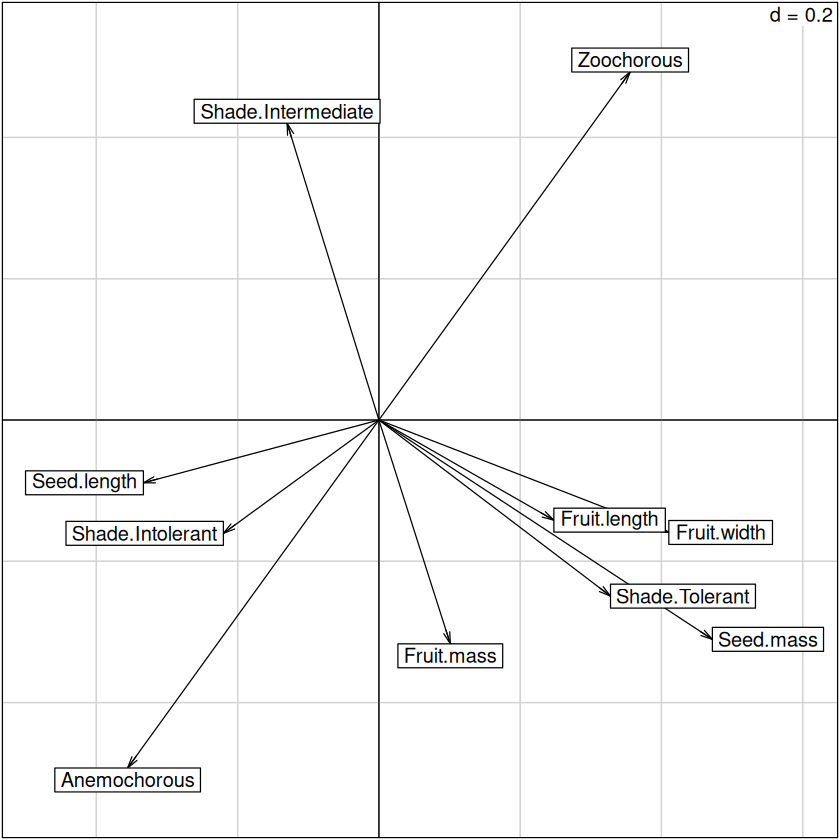

In [21]:
s.arrow(rlq1$c1)


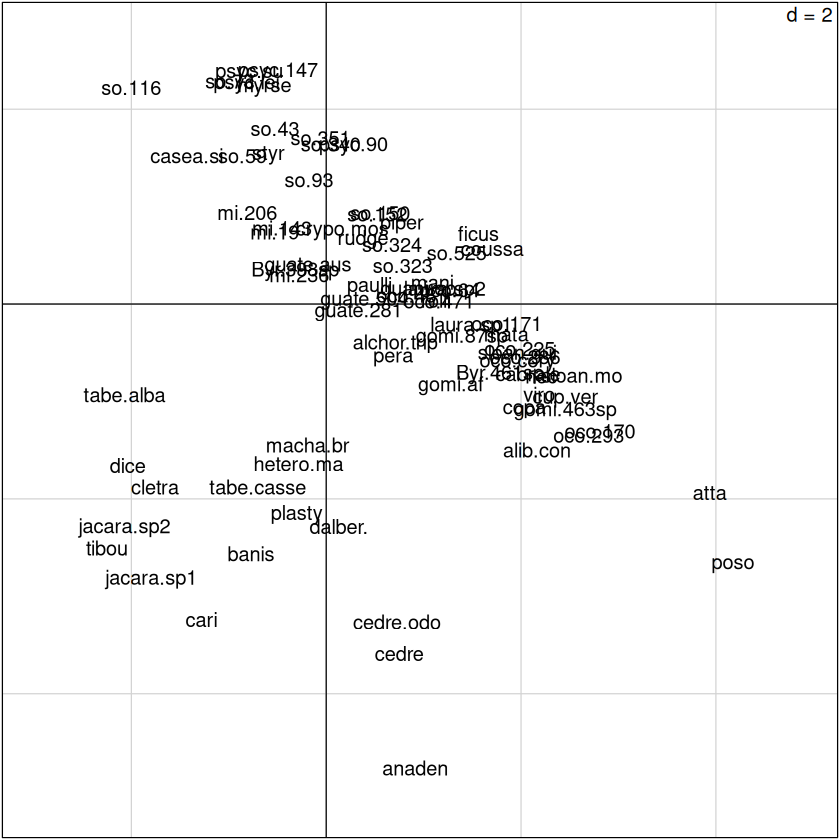

In [22]:
s.label(rlq1$lQ, boxes = FALSE)


In [23]:
summary(rlq1)
#testrlq1 <- randtest(rlq1, modeltype = 6, nrepet = 999)
#the percentage of inertia are obtained by
rlq1$eig[1]/sum(rlq1$eig)*100 # almost 78% of the marginality in the dataset % in the firt axes
rlq1$eig[2]/sum(rlq1$eig)*100 # together , the 2 axes account for 95% of the marginality

RLQ analysis

Class: rlq dudi
Call: rlq(dudiR = dudienv1, dudiL = coa1, dudiQ = duditrait1, scannf = FALSE, 
    nf = 2)

Total inertia: 0.1841

Eigenvalues:
      Ax1       Ax2       Ax3       Ax4       Ax5 
0.1449731 0.0318701 0.0041486 0.0020735 0.0006255 

Projected inertia (%):
    Ax1     Ax2     Ax3     Ax4     Ax5 
78.7273 17.3070  2.2529  1.1260  0.3397 

Cumulative projected inertia (%):
    Ax1   Ax1:2   Ax1:3   Ax1:4   Ax1:5 
  78.73   96.03   98.29   99.41   99.75 

(Only 5 dimensions (out of 7) are shown)


Eigenvalues decomposition:
         eig     covar      sdR      sdQ       corr
1 0.14497314 0.3807534 1.715815 1.457563 0.15224603
2 0.03187014 0.1785221 1.197294 1.618272 0.09213814

Inertia & coinertia R (dudienv1):
    inertia      max     ratio
1  2.944022 3.178918 0.9261080
12 4.377536 4.939165 0.8862906

Inertia & coinertia Q (duditrait1):
    inertia      max    ratio
1  2.124490 2.908563 0.730426
12 4.743295 5.409145 0.876903

Correlation L (coa1):
        corr

[1] 78.7273

[1] 17.307

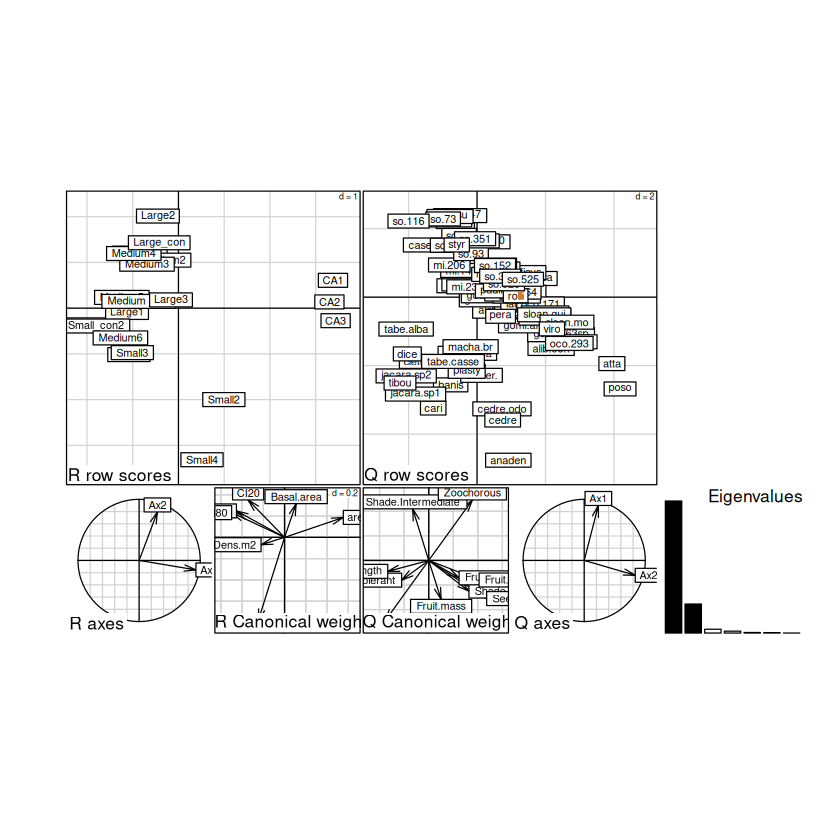

In [24]:
##plot 
par(oma=c(5.1,4.1,4.1,2.1)) 
plot(rlq1)

NULL

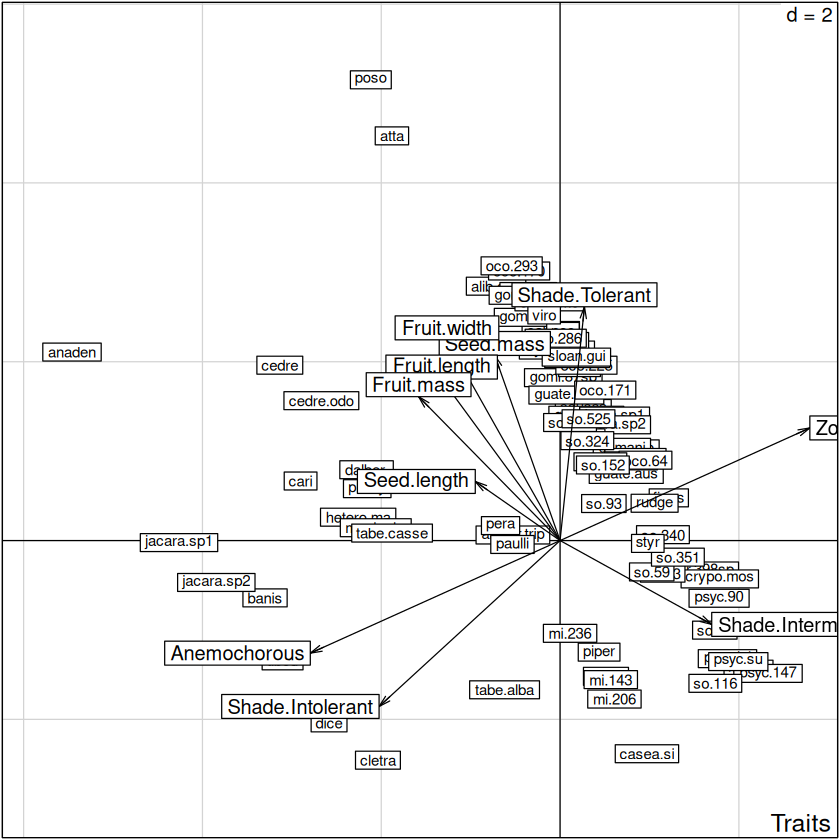

In [25]:
### ordination plot of traits
# 1. ordination of dispersal mode on functional trait space
scatter(duditrait1, posieig= "none", sub= "Traits")


NULL

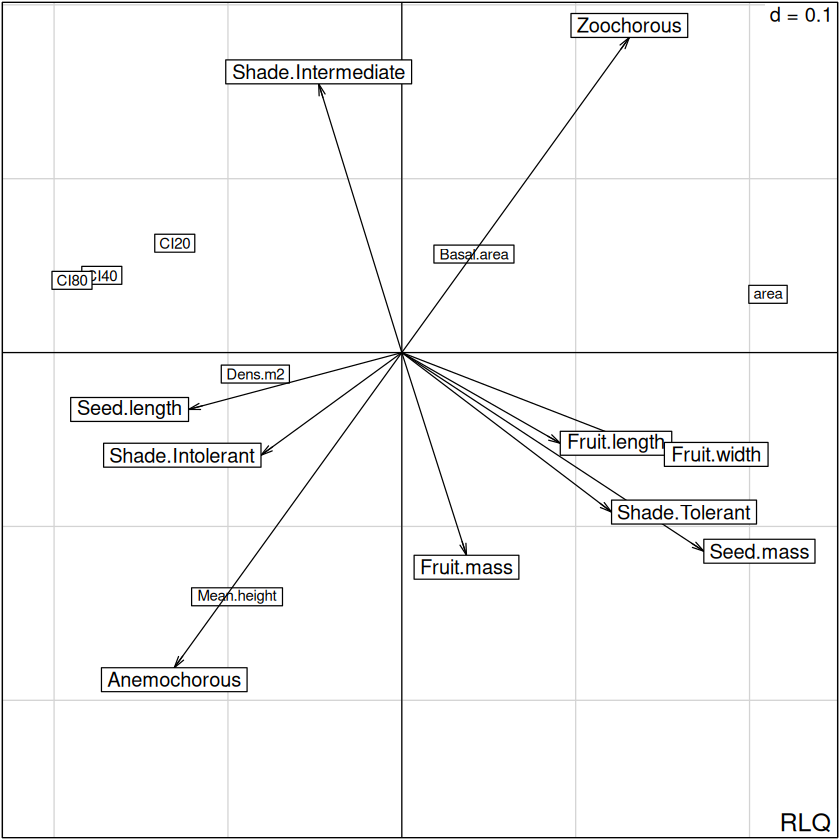

In [26]:
# 2.Ordination plot: Mean traits in the environmental space
scatter(rlq1, posieig= "none", sub= "RLQ")


NULL

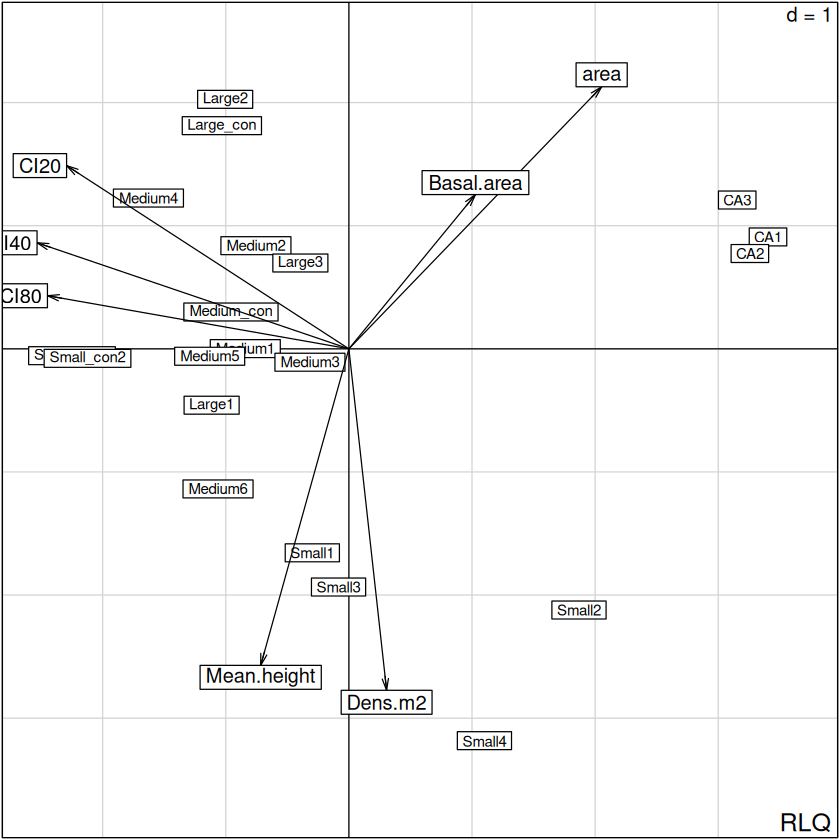

In [27]:
#3. Ordination plot :Site in the environmental space
scatter(dudienv1, sub= "RLQ", posieig= "none", 
        xax = 1, yax = 2, possub="bottomleft", csub = 2,
        col = c("blue"), main="ordination of environmental variables",
        xlab="RLQ Axis 1(45%)",ylab="RLQ Axis 2 (25%)")
#Horizontal boxplot displaying the weighted average positions 
#(points) of species  trait categories
## Bottom dots in the vertical lines are the weigthed average points of species along first RLQ axis.
# here the trait table can not be transformed
### for this analysis download again tables use env with area and without n indv.
# and occ without hellinger

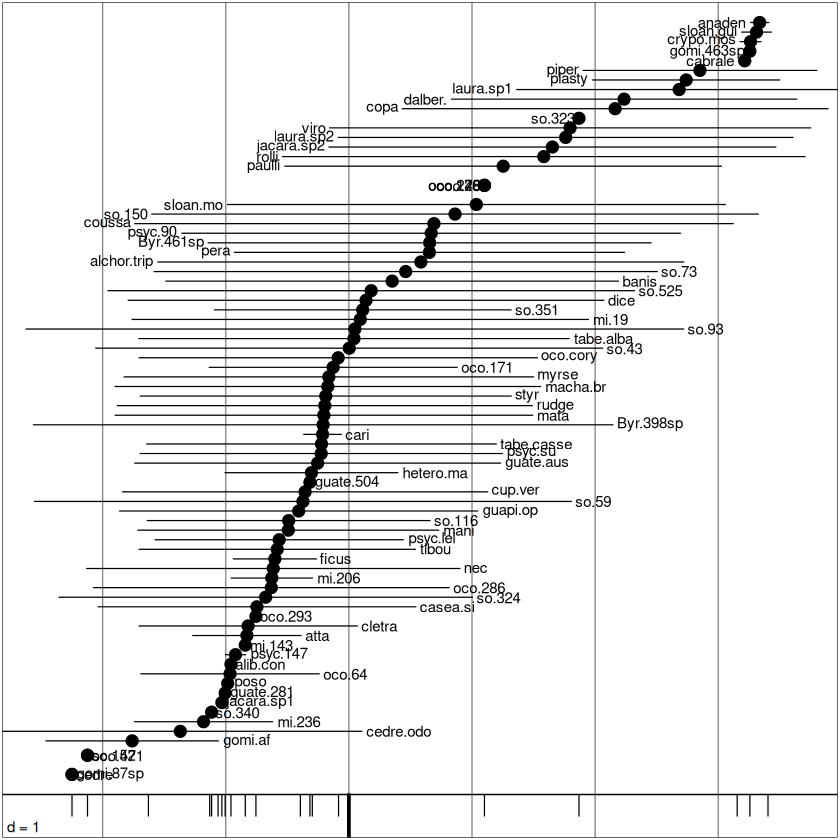

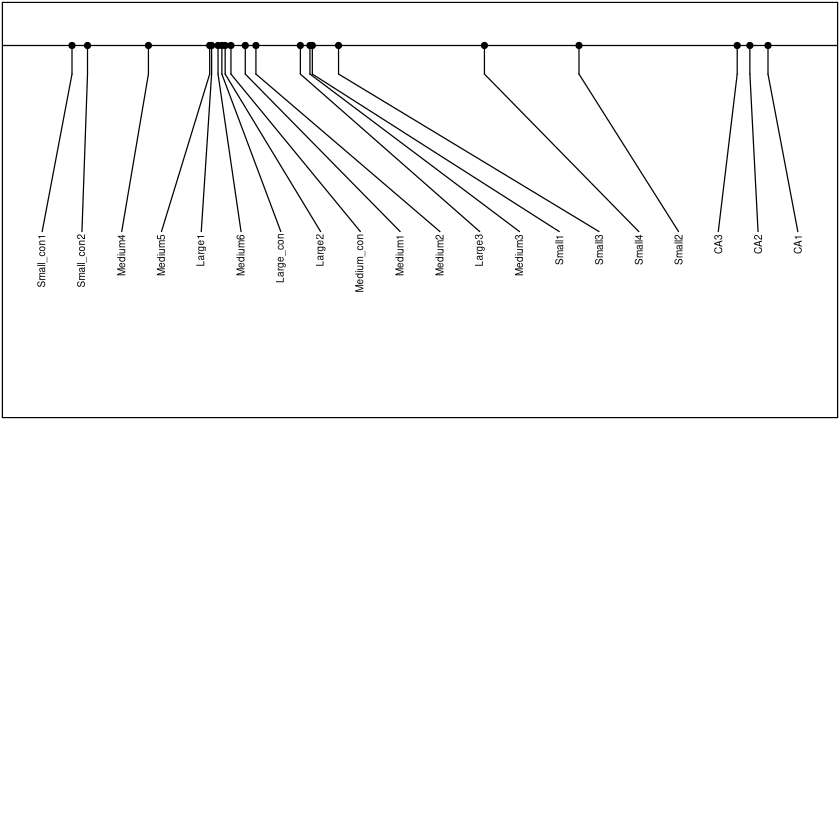

In [28]:
par(mfrow=c(1,1))         
sco.distri(dudienv1$li[,1], occ1, clab=0.75, csub=0.75, lab = colnames(occ1))
par(mfrow=c(2,1))
sco.label(dudienv1$l1[,1], row.names(env), horizontal=T,grid = F, boxes = F, reverse=T, clab=0.50, csub=0.5, lim=NULL)


[1] 43.5334817 26.1321962 14.2130705 10.7482409  2.4652360  2.2897652  0.6180095

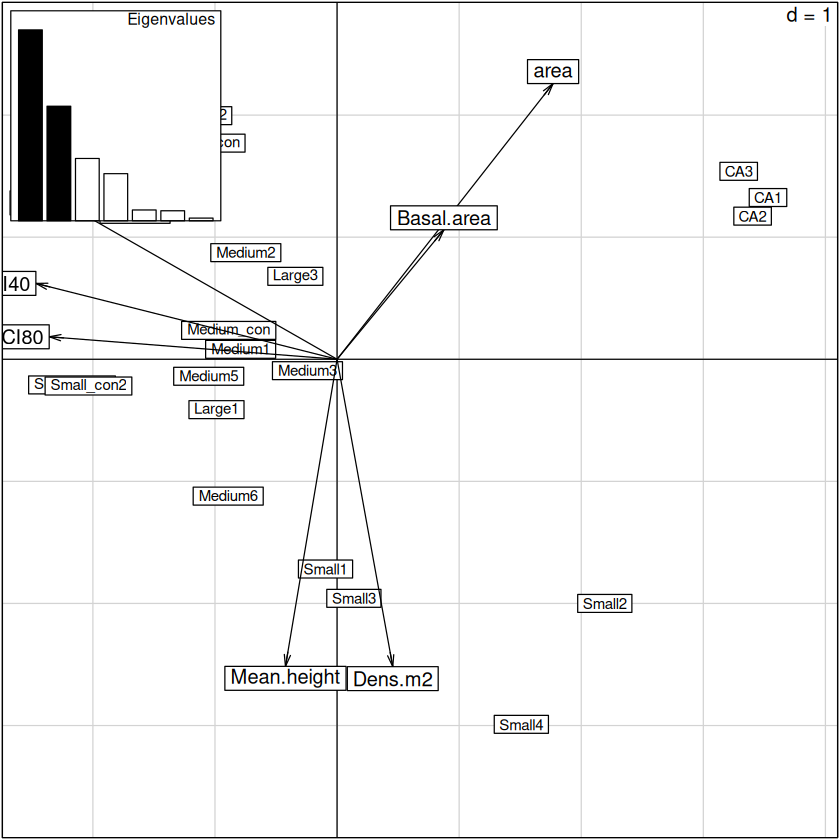

In [29]:
#Species niche description

pca.env <- dudi.pca(env, scannf=F)
scatter(pca.env)
100*pca.env$eig/sum(pca.env$eig)


[1] 43.5334817 26.1321962 14.2130705 10.7482409  2.4652360  2.2897652  0.6180095

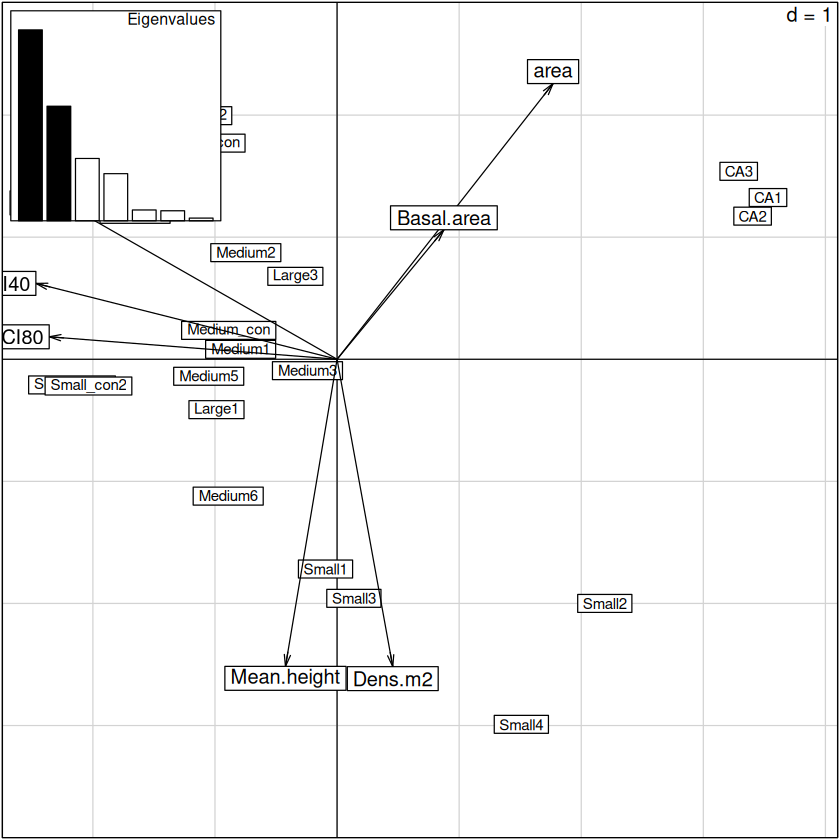

[1] 68.2384365 16.9032370  6.7198134  5.7602782  1.0607567  1.0120548  0.3054234

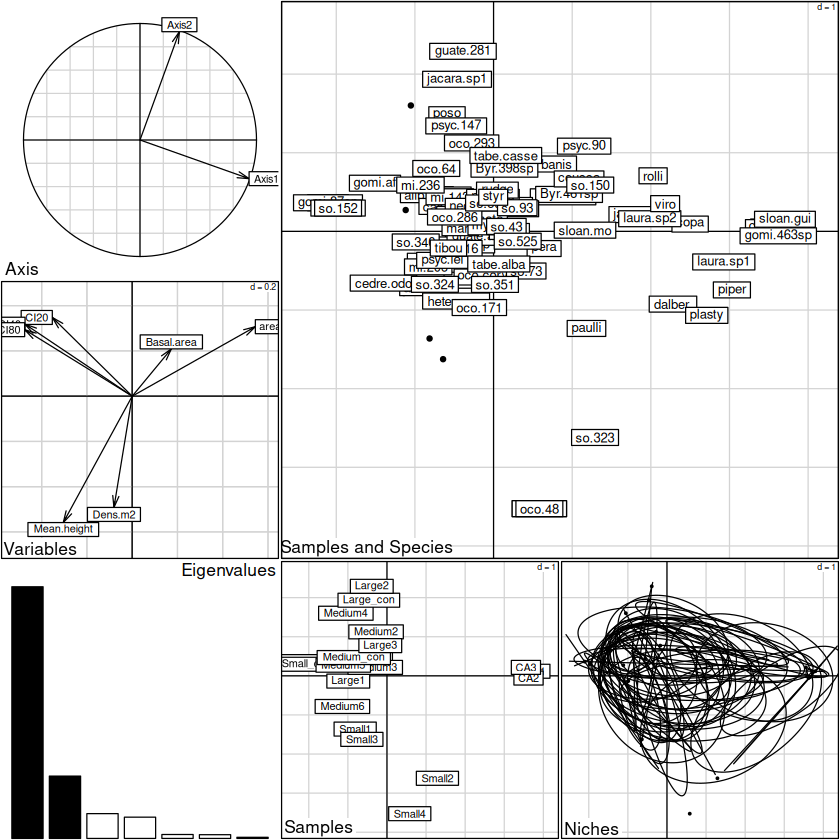

In [32]:

#Species niche description

pca.env <- dudi.pca(env, scannf=F)
scatter(pca.env)
100*pca.env$eig/sum(pca.env$eig)
omi1 <- niche(pca.env, occ1, scannf=F)
plot(omi1)
100*omi1$eig/sum(omi1$eig)

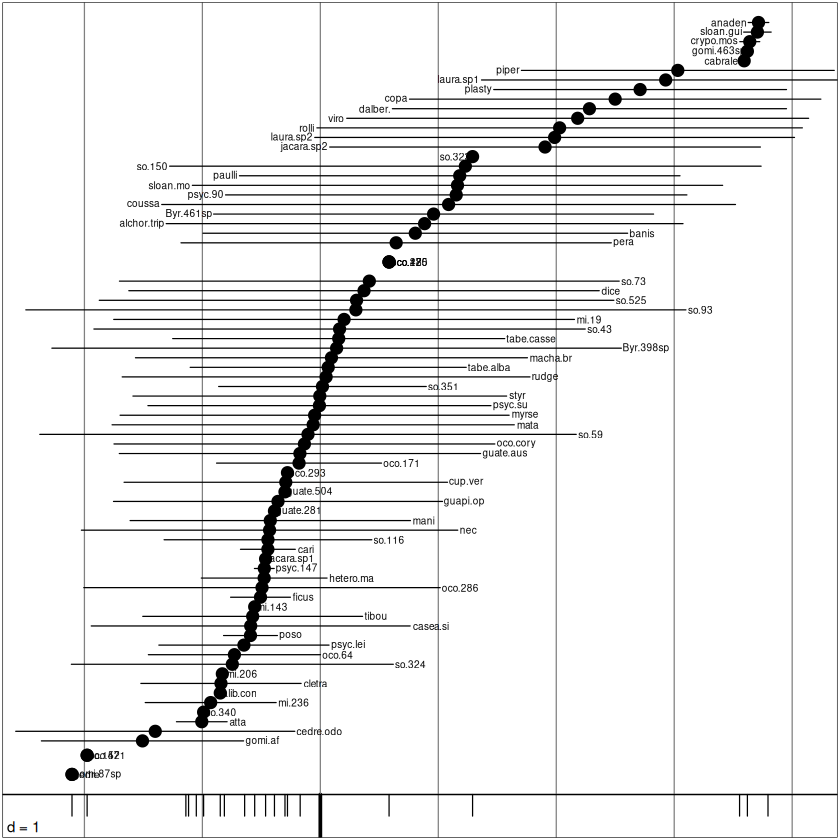

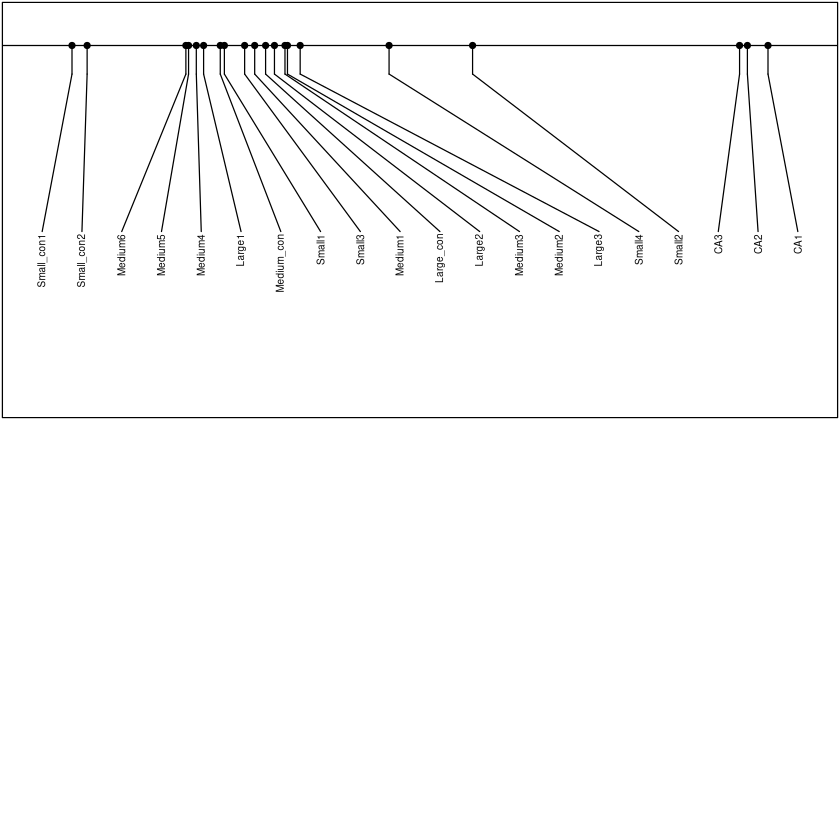

In [33]:
## niche plot
sco.distri(omi1$ls[,1], occ1, clab=0.5)
par(mfrow=c(2,1))
sco.label(omi1$ls[,1], row.names(env), horizontal=T,grid = F, boxes = F, reverse=T, clab=0.50, csub=0.5, lim=NULL)